# R7 - Cierre y selección de la configuración final

**Objetivo.** Consolidar los experimentos B0-B3 y los análisis complementarios de R7 (notebooks 00-06), documentar la selección de **B2** como protocolo final de clasificación y congelar el protocolo de evaluación de R8 **antes** de utilizar el conjunto test.

**Alcance.** El notebook solo **lee artefactos existentes** y calcula tablas derivadas. No entrena, no modifica checkpoints, notebooks, resultados ni configuraciones anteriores, y **no usa ni inspecciona test** (ni predicciones ni métricas). No implementa R8 ni extrae conclusiones de desempeño final.

| Config. | Cambio frente a B0 (ConvNeXt-Tiny, representación A, semillas 42, 43 y 44) |
|---|---|
| B0 | Entropía cruzada con pesos de clase por frecuencia inversa (α = 1.0); referencia |
| B1 | Sin early stopping (30 épocas) |
| B2 | Entropía cruzada con pesos atenuados (α = 0.5) |
| B3 | Focal Loss ponderada (γ = 2.0, pesos α = 1.0) |

Criterios comunes: AP en validation como métrica principal (regla de R6), checkpoint de máximo `val_roc_auc` y umbral fijo 0.5.

**Terminología.** Las 22 imágenes de `y_true = 1` en validation son *positivas operacionales*: la etiqueta positiva agrupa las categorías originales 6 y 7, y la categoría 6 (cistoadenoma mucinoso) no es malignidad histológica.

## 1. Configuración

In [1]:
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def locate_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    for candidate in [current_dir, *current_dir.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate

    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


PROJECT_ROOT = locate_project_root()

SEEDS = [42, 43, 44]
CLASSIFICATION_DIR = PROJECT_ROOT / "results" / "classification"
R7_DIR = CLASSIFICATION_DIR / "r7_optimizacion"
CONFIG_DIRS = {
    "B0": CLASSIFICATION_DIR / "r4_benchmark" / "convnext_tiny" / "A",
    "B1": R7_DIR / "early_stopping",
    "B2": R7_DIR / "class_weights",
    "B3": R7_DIR / "focal_loss",
}
CONFIGS = list(CONFIG_DIRS)
DESCRIPTION = {"B0": "pesos α = 1.0 (referencia)", "B1": "sin early stopping", "B2": "pesos α = 0.5", "B3": "Focal Loss γ = 2.0"}
STAT_DIR = R7_DIR / "analisis_estadistico"  # notebook 04
MAPPING_DIR = R7_DIR / "analisis_mapeo_binario"  # notebook 05
ENSEMBLE_DIR = R7_DIR / "analisis_ensamble"  # notebook 06
OUT_DIR = R7_DIR / "cierre_seleccion"  # salidas de este notebook

ACCESSED = []  # registro de rutas leídas, para comprobar que no se accede a test


def read_json(path: Path):
    ACCESSED.append(path)
    return json.loads(path.read_text(encoding="utf-8"))


def read_csv(path: Path) -> pd.DataFrame:
    ACCESSED.append(path)
    return pd.read_csv(path)


OUT_DIR.mkdir(parents=True, exist_ok=True)

## 2. Consolidación de B0-B3 desde los artefactos

Por semilla, AP, ROC-AUC, sensibilidad y especificidad (umbral 0.5) se leen de `validation_metrics.json`; las épocas, de `run_config.json`. El ΔAP, su desviación entre semillas y el IC bootstrap del 95 % se leen de las salidas del notebook 04 (`analisis_estadistico/ap_resumen_b0_b3.csv`): **no se recalculan ni se escriben a mano**. Como comprobación, el AP medio y los ΔAP por semilla derivados de los `validation_metrics.json` deben coincidir con los del notebook 04.

In [2]:
per_seed_rows = []
for config, directory in CONFIG_DIRS.items():
    for seed in SEEDS:
        metrics = read_json(directory / f"seed_{seed}" / "validation_metrics.json")
        run = read_json(directory / f"seed_{seed}" / "run_config.json")
        assert run["seed"] == seed, (config, seed)
        per_seed_rows.append(
            {
                "config": config,
                "seed": seed,
                "ap": metrics["average_precision"],
                "roc_auc": metrics["roc_auc"],
                "sensibilidad": metrics["recall_malignant"],
                "especificidad": metrics["specificity"],
                "epoca_checkpoint": run["epoch_best"],
                "epocas_ejecutadas": run["epochs_run"],
            }
        )
per_seed = pd.DataFrame(per_seed_rows)
per_seed.round(4).to_csv(OUT_DIR / "consolidado_b0_b3_por_semilla.csv", index=False)

stat = read_csv(STAT_DIR / "ap_resumen_b0_b3.csv").set_index("config")

summary_rows = []
for config in CONFIGS:
    sub = per_seed[per_seed["config"] == config].set_index("seed")
    row = {
        "config": config,
        "descripcion": DESCRIPTION[config],
        "ap_medio": sub["ap"].mean(),
        "ap_sd_semillas": sub["ap"].std(ddof=1),
        "roc_auc_medio": sub["roc_auc"].mean(),
        "roc_auc_sd": sub["roc_auc"].std(ddof=1),
        "sensibilidad_media": sub["sensibilidad"].mean(),
        "sensibilidad_sd": sub["sensibilidad"].std(ddof=1),
        "especificidad_media": sub["especificidad"].mean(),
        "especificidad_sd": sub["especificidad"].std(ddof=1),
    }
    if config != "B0":
        base = per_seed[per_seed["config"] == "B0"].set_index("seed")["ap"]
        deltas = sub["ap"] - base
        row.update(
            {
                "delta_ap_medio": deltas.mean(),
                "delta_sd_semillas": deltas.std(ddof=1),
                "semillas_delta_positivo": int((deltas > 0).sum()),
                "ic95_boot_inf": stat.loc[config, "ic95_boot_inf"],  # del notebook 04
                "ic95_boot_sup": stat.loc[config, "ic95_boot_sup"],
            }
        )
        # Coincidencia con el notebook 04 (que guarda 4 decimales)
        assert abs(row["ap_medio"] - stat.loc[config, "ap_medio"]) < 6e-5, config
        assert abs(row["delta_ap_medio"] - stat.loc[config, "delta_ap_medio"]) < 6e-5, config
        for seed in SEEDS:
            assert abs(deltas[seed] - stat.loc[config, f"delta_ap_semilla_{seed}"]) < 6e-5, (config, seed)
    else:
        assert abs(row["ap_medio"] - stat.loc["B0", "ap_medio"]) < 6e-5
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows)
summary.round(4).to_csv(OUT_DIR / "consolidado_b0_b3.csv", index=False)
print("AP medio y ΔAP por semilla coinciden con el notebook 04 (tolerancia 6e-5, por el redondeo a 4 decimales).")

display(summary[["config", "descripcion", "ap_medio", "ap_sd_semillas", "delta_ap_medio", "delta_sd_semillas", "semillas_delta_positivo", "ic95_boot_inf", "ic95_boot_sup"]].round(4))
display(summary[["config", "roc_auc_medio", "roc_auc_sd", "sensibilidad_media", "sensibilidad_sd", "especificidad_media", "especificidad_sd"]].round(4))
display(per_seed.round(4))

AP medio y ΔAP por semilla coinciden con el notebook 04 (tolerancia 6e-5, por el redondeo a 4 decimales).


,config,descripcion,ap_medio,ap_sd_semillas,delta_ap_medio,delta_sd_semillas,semillas_delta_positivo,ic95_boot_inf,ic95_boot_sup
0,B0,pesos α = 1.0 (referencia),0.5413,0.0438,NaN,NaN,NaN,NaN,NaN
1,B1,sin early stopping,0.5599,0.0867,0.0186,0.0868,2.0,-0.0452,0.0919
2,B2,pesos α = 0.5,0.6114,0.0359,0.0701,0.0528,3.0,0.0044,0.1387
3,B3,Focal Loss γ = 2.0,0.5454,0.0755,0.0041,0.1192,2.0,-0.0643,0.0825


,config,roc_auc_medio,roc_auc_sd,sensibilidad_media,sensibilidad_sd,especificidad_media,especificidad_sd
0,B0,0.8434,0.0370,0.4545,0.2765,0.9157,0.1219
1,B1,0.8688,0.0253,0.4091,0.0455,0.9663,0.0195
2,B2,0.8534,0.0265,0.4545,0.1203,0.9644,0.0288
3,B3,0.8458,0.0033,0.4848,0.0525,0.9513,0.0227


,config,seed,ap,roc_auc,sensibilidad,especificidad,epoca_checkpoint,epocas_ejecutadas
0,B0,42,0.5898,0.8853,0.7727,0.7753,8,13
1,B0,43,0.5295,0.8292,0.3182,0.9775,7,8
2,B0,44,0.5046,0.8156,0.2727,0.9944,7,8
3,B1,42,0.6115,0.8889,0.4091,0.9775,23,30
4,B1,43,0.4597,0.8404,0.4545,0.9438,14,30
5,B1,44,0.6083,0.8772,0.3636,0.9775,18,30
6,B2,42,0.6050,0.8639,0.5455,0.9326,7,12
7,B2,43,0.6501,0.8731,0.5000,0.9719,7,9
8,B2,44,0.5790,0.8233,0.3182,0.9888,8,8
9,B3,42,0.4606,0.8435,0.4545,0.9382,10,10


## 3. Criterios de selección

La regla es la de R6 (mayor AP medio en validation entre semillas) aplicada a las cuatro configuraciones, con los demás indicadores reportados pero sin modificar la regla. **No se fija ninguna meta numérica**: la selección se deduce de la regla y de la consistencia entre semillas, no de un valor umbral definido después de ver los resultados. La selección no se basa en el AP de una semilla concreta: se usa la media de las tres.

In [3]:
criteria = summary[["config", "descripcion", "ap_medio"]].copy()
criteria["rango por AP medio"] = criteria["ap_medio"].rank(ascending=False).astype(int)
criteria["semillas con ΔAP > 0 (de 3)"] = summary["semillas_delta_positivo"]
criteria["IC95% bootstrap excluye 0"] = ((summary["ic95_boot_inf"] > 0) | (summary["ic95_boot_sup"] < 0)).astype("boolean").mask(summary["config"] == "B0")  # B0 es la referencia: sin ΔAP ni IC
criteria["ROC-AUC medio"] = summary["roc_auc_medio"]
criteria["ΔROC-AUC medio vs B0"] = summary["roc_auc_medio"] - summary.loc[summary["config"] == "B0", "roc_auc_medio"].iloc[0]
display(criteria.round(4))

selected = summary.loc[summary["ap_medio"].idxmax(), "config"]
b2_seeds = per_seed[per_seed["config"] == "B2"].set_index("seed")["ap"]
best_single = per_seed.loc[per_seed["ap"].idxmax()]
print(f"Configuración con mayor AP medio: {selected}.")
print(f"Mejor corrida individual: {best_single['config']} semilla {int(best_single['seed'])} (AP {best_single['ap']:.4f}); no se usa para elegir semilla.")
assert selected == "B2"
assert summary.loc[summary["config"] == "B2", "semillas_delta_positivo"].iloc[0] == 3

,config,descripcion,ap_medio,rango por AP medio,semillas con ΔAP > 0 (de 3),IC95% bootstrap excluye 0,ROC-AUC medio,ΔROC-AUC medio vs B0
0,B0,pesos α = 1.0 (referencia),0.5413,4,NaN,<NA>,0.8434,0.0000
1,B1,sin early stopping,0.5599,2,2.0,False,0.8688,0.0255
2,B2,pesos α = 0.5,0.6114,1,3.0,True,0.8534,0.0100
3,B3,Focal Loss γ = 2.0,0.5454,3,2.0,False,0.8458,0.0025


Configuración con mayor AP medio: B2.
Mejor corrida individual: B2 semilla 43 (AP 0.6501); no se usa para elegir semilla.


## 4. Evidencia complementaria (notebooks 05 y 06)

Se leen, sin recalcular, las salidas del análisis del mapeo binario (05) y del ensamble de semillas (06), y se comprueba su coherencia con la consolidación anterior.

In [4]:
# --- Notebook 06: ensamble de semillas
ens_individual = read_csv(ENSEMBLE_DIR / "ap_individual_vs_ensamble.csv").set_index("config")
ens_delta = read_csv(ENSEMBLE_DIR / "delta_ap_ensamble_b2_vs_b0.csv").iloc[0]
ens_metrics = read_csv(ENSEMBLE_DIR / "metricas_ensamble.csv").set_index("modelo")

for config in ("B0", "B2"):
    mean_ap = summary.loc[summary["config"] == config, "ap_medio"].iloc[0]
    assert abs(mean_ap - ens_individual.loc[config, "AP medio individual"]) < 6e-5, config  # coincide con 06
ens_b0, ens_b2 = ens_metrics.loc["Ensamble B0"], ens_metrics.loc["Ensamble B2"]
assert abs(ens_delta["ΔAP observado"] - (ens_b2["ap"] - ens_b0["ap"])) < 6e-5

# --- Notebook 05: mapeo binario
mapping = read_csv(MAPPING_DIR / "metricas_por_tarea.csv")
main_task = mapping[mapping["tarea"].str.startswith("principal")].set_index(["config", "seed"])["ap"]
alt_task = mapping[mapping["tarea"].str.startswith("secundaria")].set_index(["config", "seed"])["ap"]
for config in ("B0", "B2"):
    for seed in SEEDS:
        ap_json = per_seed[(per_seed["config"] == config) & (per_seed["seed"] == seed)]["ap"].iloc[0]
        assert abs(ap_json - main_task[(config, seed)]) < 6e-5, (config, seed)  # coincide con 05
mapping_comparison = read_csv(MAPPING_DIR / "comparacion_b0_b2_por_semilla.csv").set_index("seed")  # ΔAP por semilla calculados en el notebook 05
alt_delta = mapping_comparison["ap_cat7_vs_0a5_delta"]
main_delta = mapping_comparison["ap_principal_delta"]
print("Coherencia comprobada con los notebooks 05 y 06 (AP medio individual, AP por semilla de la tarea principal, ΔAP de los ensambles).")

supplementary = pd.DataFrame(
    [
        {"fuente": "06", "medida": "AP medio de los 3 modelos individuales", "B0": ens_individual.loc["B0", "AP medio individual"], "B2": ens_individual.loc["B2", "AP medio individual"]},
        {"fuente": "06", "medida": "AP del ensamble de 3 semillas", "B0": ens_b0["ap"], "B2": ens_b2["ap"]},
        {"fuente": "06", "medida": "ROC-AUC del ensamble de 3 semillas", "B0": ens_b0["roc_auc"], "B2": ens_b2["roc_auc"]},
        {"fuente": "05", "medida": "AP tarea principal (0-5 vs 6-7), media de 3 semillas", "B0": main_task["B0"].mean(), "B2": main_task["B2"].mean()},
        {"fuente": "05", "medida": "AP tarea secundaria (0-5 vs 7), media de 3 semillas", "B0": alt_task["B0"].mean(), "B2": alt_task["B2"].mean()},
    ]
)
supplementary["B2 - B0"] = supplementary["B2"] - supplementary["B0"]
supplementary["IC95% bootstrap inf"] = np.nan
supplementary["IC95% bootstrap sup"] = np.nan
supplementary.loc[supplementary["medida"] == "AP del ensamble de 3 semillas", ["IC95% bootstrap inf", "IC95% bootstrap sup"]] = [ens_delta["IC95% inf"], ens_delta["IC95% sup"]]  # del notebook 06
supplementary["nota"] = ""
supplementary.loc[supplementary["medida"].str.startswith("AP tarea secundaria"), "nota"] = "subconjunto de 185 imágenes; no comparable con la tarea principal; ΔAP por semilla: " + ", ".join(f"{alt_delta[s]:+.4f}" for s in SEEDS)
supplementary.loc[supplementary["medida"].str.startswith("AP tarea principal"), "nota"] = "ΔAP por semilla: " + ", ".join(f"{main_delta[s]:+.4f}" for s in SEEDS)
supplementary.loc[supplementary["medida"] == "AP del ensamble de 3 semillas", "nota"] = "IC del ΔAP entre ensambles (notebook 06); 3 inferencias por imagen frente a 1"
supplementary.round(4).to_csv(OUT_DIR / "evidencia_complementaria.csv", index=False)
display(supplementary.round(4))
print(f"ΔAP entre ensambles: {ens_delta['ΔAP observado']:+.4f}, IC95% [{ens_delta['IC95% inf']:+.4f}, {ens_delta['IC95% sup']:+.4f}]; inferencias por imagen: individual 1, ensamble 3.")
print(f"Tarea secundaria, ΔAP B2 - B0 por semilla (notebook 05): {', '.join(f'{alt_delta[s]:+.4f}' for s in SEEDS)}.")

Coherencia comprobada con los notebooks 05 y 06 (AP medio individual, AP por semilla de la tarea principal, ΔAP de los ensambles).


,fuente,medida,B0,B2,B2 - B0,IC95% bootstrap inf,IC95% bootstrap sup,nota
0,06,AP medio de los 3 modelos individuales,0.5413,0.6114,0.0701,NaN,NaN,
1,06,AP del ensamble de 3 semillas,0.6029,0.6321,0.0292,-0.0609,0.1266,IC del ΔAP entre ensambles (notebook 06); 3 in...
2,06,ROC-AUC del ensamble de 3 semillas,0.9014,0.8693,-0.0321,NaN,NaN,
3,05,"AP tarea principal (0-5 vs 6-7), media de 3 se...",0.5413,0.6114,0.0701,NaN,NaN,"ΔAP por semilla: +0.0153, +0.1205, +0.0744"
4,05,"AP tarea secundaria (0-5 vs 7), media de 3 sem...",0.5146,0.5164,0.0018,NaN,NaN,subconjunto de 185 imágenes; no comparable con...


ΔAP entre ensambles: +0.0292, IC95% [-0.0609, +0.1266]; inferencias por imagen: individual 1, ensamble 3.
Tarea secundaria, ΔAP B2 - B0 por semilla (notebook 05): -0.0540, +0.0764, -0.0172.


## 5. Figura

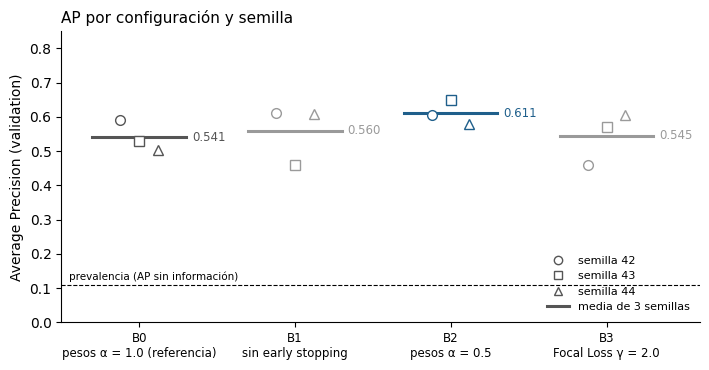

In [5]:
colors = {"B0": "#555555", "B1": "#9a9a9a", "B2": "#1f5f8b", "B3": "#9a9a9a"}
markers = {42: "o", 43: "s", 44: "^"}
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for x_pos, config in enumerate(CONFIGS):
    sub = per_seed[per_seed["config"] == config]
    mean_ap = sub["ap"].mean()
    ax.plot([x_pos - 0.3, x_pos + 0.3], [mean_ap, mean_ap], color=colors[config], lw=2.2, zorder=2)
    for _, row in sub.iterrows():
        ax.plot(x_pos + (row["seed"] - 43) * 0.12, row["ap"], markers[int(row["seed"])], color=colors[config], mfc="white", ms=7, zorder=3)
    ax.annotate(f"{mean_ap:.3f}", (x_pos + 0.32, mean_ap), xytext=(2, 0), textcoords="offset points", va="center", fontsize=8.5, color=colors[config])
ax.axhline(22 / 200, color="black", lw=0.8, ls="--")
ax.annotate("prevalencia (AP sin información)", (-0.45, 22 / 200), xytext=(0, 3), textcoords="offset points", fontsize=7.5)
ax.set_xticks(range(len(CONFIGS)))
ax.set_xticklabels([f"{config}\n{DESCRIPTION[config]}" for config in CONFIGS], fontsize=8.5)
ax.set_xlim(-0.5, len(CONFIGS) - 0.4)
ax.set_ylim(0, 0.85)
ax.set_ylabel("Average Precision (validation)")
ax.set_title("AP por configuración y semilla", loc="left", fontsize=11)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
handles = [plt.Line2D([], [], marker=markers[s], color="#555555", mfc="white", ls="", label=f"semilla {s}") for s in SEEDS]
handles.append(plt.Line2D([], [], color="#555555", lw=2.2, label="media de 3 semillas"))
ax.legend(handles=handles, frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(OUT_DIR / "ap_por_semilla_b0_b3.png", dpi=200)
plt.show()

## 6. Decisión adoptada

**Se selecciona B2** (entropía cruzada ponderada con α = 0.5, ConvNeXt-Tiny, representación A) **como protocolo final de clasificación**; B0 se conserva como referencia experimental. Se adopta la configuración (con sus tres semillas), no una semilla individual: ninguna semilla se elige por su AP de validation.

**Por qué B2.**

- Tiene el mayor AP medio de B0-B3 y mejora el AP de B0 en las tres semillas (tabla de la sección 2).
- El análisis estadístico exploratorio (notebook 04) es favorable: el IC bootstrap del 95 % del ΔAP medio frente a B0 excluye el cero con un límite inferior muy cercano a él.
- Es un cambio mínimo y conocido: solo atenúa los pesos de clase; mantiene la pérdida, el early stopping y el protocolo de selección de checkpoints de R4-R6.

**Por qué no B1, B3 ni el ensamble como configuración principal.**

- **B1 (sin early stopping):** ΔAP medio pequeño con IC que incluye el cero; mejora el AP en 2 de 3 semillas y el ΔAP cambia de signo entre semillas. Tiene el ROC-AUC medio más alto de las cuatro configuraciones (sección 2), pero la regla de selección es por AP y, con AP, no se distingue de la variabilidad; además, sin early stopping las corridas ejecutan las 30 épocas.
- **B3 (Focal Loss):** ΔAP medio casi nulo con IC que incluye el cero; cambia de signo entre semillas (con una caída marcada en la semilla 42).
- **Ensamble de tres semillas de B2:** su ΔAP frente al ensamble de B0 es menor que el de los modelos individuales y su IC incluye el cero; su ROC-AUC es menor que el del ensamble de B0; y exige tres inferencias por imagen en lugar de una (latencia y memoria no medidas). No sustituye a la configuración individual. El ensamble de seis modelos fue solo exploratorio.

**Mapeo binario (notebook 05).** El IOV propuesto de mapeo binario, tomado del informe actualizado y **pendiente de aprobación formal del asesor**, indica: «Se realiza un análisis de sensibilidad del desempeño respecto del mapeo de las categorías originales a la etiqueta binaria, documentando su influencia y las limitaciones de interpretación». El notebook 05 es ese análisis. La clase positiva operacional agrupa las categorías originales 6 y 7; la categoría 6 es el cistoadenoma mucinoso y **no es malignidad histológica**. Lo medido, por tanto, es la separación de 0-5 frente a 6-7 y **no equivale a demostrar la detección de malignidad histológica**. En el análisis secundario (categoría 7 frente a 0-5, 185 imágenes, solo 7 positivas) el AP alternativo **no mostró mejora consistente** de B2 frente a B0: el ΔAP cambia de signo entre semillas.

**Limitaciones de la selección.**

- La selección se hizo **sobre este mismo validation**: el checkpoint de cada corrida se eligió por `val_roc_auc` en validation y B2 se conservó tras compararse allí con B1 y B3. El IC bootstrap del 95 % mide solo la incertidumbre por remuestreo de imágenes, con los modelos entrenados fijos; **no corrige la selección entre experimentos ni es una prueba confirmatoria independiente**, y el sesgo probable es favorable a B2.
- Solo hay 22 positivas operacionales y tres semillas; la variabilidad entre semillas y el remuestreo de imágenes son fuentes de incertidumbre distintas y no se combinan.
- No hay identificadores de paciente: una dependencia entre imágenes haría los intervalos demasiado estrechos.
- Los pesos distintos modifican la distribución de probabilidades; sensibilidad y especificidad al 0.5 se comparan solo de forma descriptiva.

## 7. Protocolo congelado para R8

Define cómo se usará el conjunto test **una sola vez**, con B0 y B2 ya definidos. **Este notebook no implementa R8 ni usa test.** Lo siguiente queda congelado a partir de este cierre:

1. **Modelos.** Evaluar B0 y B2 en las semillas 42, 43 y 44, con los checkpoints `best_auc.pth` de cada corrida (seis modelos). Sin ensambles.
2. **Datos.** Exactamente las mismas imágenes de test para ambas configuraciones, con el preprocesamiento de evaluación de R4-R6 y sin data augmentation.
3. **Sin ajuste con test.** No reentrenar, recalibrar, ajustar umbrales ni seleccionar modelos, semillas o configuraciones con resultados de test. La decisión de que B2 es la configuración final ya está tomada.
4. **Umbral fijo 0.5** (`probabilidad >= 0.5` es positiva).
5. **Métricas por semilla y configuración:** AP, ROC-AUC, sensibilidad, especificidad, precisión, F1, balanced accuracy y matriz de confusión. Además, medias y desviaciones estándar muestrales (n − 1) entre las tres semillas.
6. **Comparación B2 frente a B0.** Diferencia media de AP (media de los tres ΔAP por semilla) con IC percentil del 95 % por **bootstrap pareado y estratificado por imagen**: 2000 remuestreos, semilla fija, remuestreo dentro de cada clase y **los mismos índices para todas las semillas y ambas configuraciones**. R8 utilizará **2000 remuestreos bootstrap y la semilla 20260101**, según este protocolo ya congelado.
7. **Dos fuentes de incertidumbre separadas.** El IC bootstrap mide el remuestreo de imágenes con los modelos fijos; la variabilidad entre semillas se reporta aparte (desviaciones y ΔAP por semilla). No se combinan ni se presentan como prueba de significancia.
8. **Limitaciones a declarar:** (a) no hay identificadores de paciente, por lo que no se puede asumir independencia entre imágenes; (b) hubo **acceso exploratorio previo al conjunto test** en etapas anteriores del proyecto (evaluaciones iniciales de segmentación y de baselines, y una inspección preliminar), de modo que test no es virgen; (c) B2 se seleccionó sobre validation.
9. **Interpretación.** Un intervalo favorable no se interpreta como demostración automática de validez clínica, y los resultados no equivalen a detección de malignidad histológica (categorías 6 y 7 agrupadas).
10. **Sin metas retrospectivas.** No se define ninguna meta numérica de desempeño después de ver resultados; cualquier resultado de test se reporta tal cual.

La siguiente celda guarda estos parámetros en `protocolo_r8_congelado.json`, leyendo del `run_config.json` de cada corrida los valores que no se escriben a mano (pesos de clase, umbral, hiperparámetros), y comprueba que B2 solo difiere de B0 en lo previsto.

In [6]:
FROZEN_KEYS = [
    "architecture", "condition", "csv_path", "image_dir", "train_samples", "validation_samples", "pretrained", "freeze_backbone", "num_classes",
    "batch_size", "epochs_max", "learning_rate", "weight_decay", "optimizer", "use_amp", "patience", "min_delta", "threshold", "scheduler", "checkpoint_criterion",
]
runs = {(config, seed): read_json(CONFIG_DIRS[config] / f"seed_{seed}" / "run_config.json") for config in ("B0", "B2") for seed in SEEDS}

for seed in SEEDS:
    for key in FROZEN_KEYS:
        assert runs[("B0", seed)][key] == runs[("B2", seed)][key], (seed, key)  # B2 solo cambia los pesos de clase
for config in ("B0", "B2"):
    weights = [tuple(runs[(config, seed)]["class_weights"]) for seed in SEEDS]
    assert len(set(weights)) == 1, config  # mismos pesos en las tres semillas
    assert all(runs[(config, seed)]["threshold"] == 0.5 for seed in SEEDS)
assert runs[("B2", 42)]["class_weight_alpha"] == 0.5 and "class_weight_alpha" not in runs[("B0", 42)]
assert runs[("B0", 42)]["class_weights"] != runs[("B2", 42)]["class_weights"]
print("Configuración congelada: B0 y B2 comparten los hiperparámetros; solo difieren los pesos de clase (y la etiqueta del experimento).")

protocol = {
    "etapa": "R8 - evaluacion final en test (protocolo congelado en el cierre de R7)",
    "estado": "congelado antes de usar test; no implementado",
    "modelos": {
        "arquitectura": runs[("B0", 42)]["architecture"],
        "representacion": runs[("B0", 42)]["condition"],
        "configuraciones": {
            "B0": {"class_weights": runs[("B0", 42)]["class_weights"], "rol": "referencia", "carpeta": str(CONFIG_DIRS["B0"].relative_to(PROJECT_ROOT).as_posix())},
            "B2": {"class_weights": runs[("B2", 42)]["class_weights"], "class_weight_alpha": runs[("B2", 42)]["class_weight_alpha"], "rol": "protocolo final de clasificacion", "carpeta": str(CONFIG_DIRS["B2"].relative_to(PROJECT_ROOT).as_posix())},
        },
        "semillas": SEEDS,
        "checkpoint": "best_auc.pth (maximo val_roc_auc, seleccionado en validation)",
        "total_modelos": 6,
        "ensambles": False,
    },
    "datos": {"conjunto": "test", "mismas_imagenes_para_ambas_configuraciones": True, "augmentation": False},
    "prohibido_con_test": ["reentrenar", "recalibrar", "ajustar umbrales", "seleccionar modelos, semillas o configuraciones", "definir metas numericas retrospectivas"],
    "umbral": runs[("B2", 42)]["threshold"],
    "metricas_por_semilla": ["average_precision", "roc_auc", "sensibilidad", "especificidad", "precision", "f1", "balanced_accuracy", "matriz_de_confusion"],
    "resumen_entre_semillas": {"estadisticos": ["media", "desviacion_estandar_muestral_n_menos_1"]},
    "comparacion_b2_vs_b0": {
        "estadistico": "media de los tres delta AP por semilla (B2 - B0)",
        "intervalo": "percentil 95 % por bootstrap pareado y estratificado por imagen",
        "n_bootstrap": 2000,
        "semilla_bootstrap": 20260101,
        "indices": "los mismos para todas las semillas y ambas configuraciones; remuestreo dentro de cada clase",
        "incertidumbres_separadas": ["remuestreo de imagenes (bootstrap)", "variabilidad entre semillas"],
    },
    "limitaciones_a_declarar": ["sin identificadores de paciente: no se asume independencia entre imagenes", "acceso exploratorio previo al conjunto test", "B2 seleccionado sobre validation", "categorias 6 y 7 agrupadas en la clase positiva operacional; la categoria 6 no es malignidad histologica"],
    "interpretacion": "un intervalo favorable no se interpreta como validez clinica",
    "iov_mapeo_binario": {
        "texto": "Se realiza un análisis de sensibilidad del desempeño respecto del mapeo de las categorías originales a la etiqueta binaria, documentando su influencia y las limitaciones de interpretación",
        "origen": "informe actualizado",
        "estado": "propuesto; pendiente de aprobación formal del asesor",
    },
    "registro_previo_a_la_evaluacion": {
        "commit_git": "registrar el hash completo del commit, con el árbol de trabajo limpio, antes de evaluar",
        "sha256_particiones": "registrar el SHA-256 del archivo de particiones usado (csv_path de run_config.json) antes de evaluar",
        "sha256_checkpoints": "registrar el SHA-256 de los seis best_auc.pth antes de evaluar y comprobarlo al evaluar",
        "inventario_preliminar": "precomprobaciones_r8_archivos.csv (entorno local; no sustituye el registro anterior)",
    },
}
(OUT_DIR / "protocolo_r8_congelado.json").write_text(json.dumps(protocol, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
print(json.dumps({k: protocol[k] for k in ("umbral", "comparacion_b2_vs_b0")}, indent=2, ensure_ascii=False))

Configuración congelada: B0 y B2 comparten los hiperparámetros; solo difieren los pesos de clase (y la etiqueta del experimento).
{
  "umbral": 0.5,
  "comparacion_b2_vs_b0": {
    "estadistico": "media de los tres delta AP por semilla (B2 - B0)",
    "intervalo": "percentil 95 % por bootstrap pareado y estratificado por imagen",
    "n_bootstrap": 2000,
    "semilla_bootstrap": 20260101,
    "indices": "los mismos para todas las semillas y ambas configuraciones; remuestreo dentro de cada clase",
    "incertidumbres_separadas": [
      "remuestreo de imagenes (bootstrap)",
      "variabilidad entre semillas"
    ]
  }
}


## 8. Comprobaciones previas a R8

`precomprobaciones_r8_archivos.csv` es un **inventario preliminar del entorno local**, no el registro de congelación. Los `*.pth` están excluidos de Git (`.gitignore`), por lo que su presencia depende de la máquina: **el notebook no falla si faltan**, informa su estado. **La ausencia de los checkpoints de B2 en esta máquina no significa que estén perdidos**: se entrenaron en el entorno de entrenamiento remoto y deben verificarse allí antes de R8. Para cada archivo se registran existencia, tamaño y SHA-256 (solo si existe); se incluyen también los dos manifiestos de partición (solo se calcula su hash; no se leen sus filas). Los hashes definitivos de los seis `best_auc.pth` deben fijarse en el entorno donde estén. No se abre ningún archivo de test.

In [7]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


FILES = ["best_auc.pth", "run_config.json", "best_auc_meta.json", "validation_metrics.json", "val_predictions_best_auc.csv"]
manifest_rows = []
for config in ("B0", "B2"):
    for seed in SEEDS:
        folder = CONFIG_DIRS[config] / f"seed_{seed}"
        for name in FILES:
            path = folder / name
            exists = path.is_file()
            if exists:
                ACCESSED.append(path)
            manifest_rows.append(
                {
                    "config": config,
                    "seed": seed,
                    "archivo": name,
                    "ruta": path.relative_to(PROJECT_ROOT).as_posix(),
                    "existe": exists,
                    "bytes": path.stat().st_size if exists else None,
                    "sha256": sha256(path) if exists else None,
                }
            )

# Manifiestos de partición: solo se calcula el hash (no se leen sus filas). El operativo es el csv_path de los run_config.
csv_paths = {runs[key]["csv_path"] for key in runs}
assert len(csv_paths) == 1, csv_paths
for role, relative in [("operativo (csv_path de run_config)", csv_paths.pop()), ("canónico", "configs/splits/mmotu_experimental_split.csv")]:
    path = PROJECT_ROOT / relative
    ACCESSED.append(path)
    manifest_rows.append({"config": "partición", "seed": None, "archivo": f"{path.name} ({role})", "ruta": relative, "existe": path.is_file(), "bytes": path.stat().st_size, "sha256": sha256(path)})

manifest = pd.DataFrame(manifest_rows)
manifest["seed"] = manifest["seed"].astype("Int64")
manifest["observacion"] = "inventario preliminar del entorno local"
missing_pth = (manifest["archivo"] == "best_auc.pth") & ~manifest["existe"]
manifest.loc[missing_pth, "observacion"] = "no presente en el entorno local (no implica pérdida): verificar en el entorno de entrenamiento antes de R8"
manifest.to_csv(OUT_DIR / "precomprobaciones_r8_archivos.csv", index=False)

checkpoints = manifest[manifest["archivo"] == "best_auc.pth"]
display(checkpoints[["config", "seed", "existe", "bytes"]])

checks = []
for config in ("B0", "B2"):
    for seed in SEEDS:
        run = runs[(config, seed)]
        meta = read_json(CONFIG_DIRS[config] / f"seed_{seed}" / "best_auc_meta.json")
        checks.append(
            {
                "config": config,
                "seed": seed,
                "semilla del run_config = carpeta": run["seed"] == seed,
                "checkpoint registrado": run["checkpoint_file"] == "best_auc.pth",
                "criterio = max val_roc_auc": meta["criterion"] == "max val_roc_auc" and run["checkpoint_criterion"].startswith("max val_roc_auc"),
                "época del checkpoint coherente": meta["epoch"] == run["epoch_best"],
                "umbral 0.5": run["threshold"] == 0.5,
            }
        )
checks = pd.DataFrame(checks)
display(checks)
assert checks.drop(columns=["config", "seed"]).all().all()

# Prevención de accesos accidentales a test: ninguna ruta leída contiene un componente 'test'
assert not any("test" in part.lower() for path in ACCESSED for part in path.relative_to(PROJECT_ROOT).parts), "Se accedió a una ruta de test"
print(f"{len(ACCESSED)} lecturas de archivos, ninguna en rutas de test (no se leyeron las filas de ninguna partición ni imágenes; de los manifiestos solo se calculó el hash).")

present = checkpoints.groupby("config")["existe"].sum().astype(int).to_dict()
print("Checkpoints best_auc.pth presentes en esta máquina (de 3):", present)
missing = checkpoints.loc[~checkpoints["existe"], ["config", "seed"]]
if len(missing):
    print("No están en esta máquina:", ", ".join(f"{c} semilla {s}" for c, s in missing.itertuples(index=False)), "(no implica pérdida) -> verificar en el entorno de entrenamiento antes de R8.")

,config,seed,existe,bytes
0,B0,42,True,111353152.0
5,B0,43,True,111353152.0
10,B0,44,True,111353152.0
15,B2,42,False,NaN
20,B2,43,False,NaN
25,B2,44,False,NaN


,config,seed,semilla del run_config = carpeta,checkpoint registrado,criterio = max val_roc_auc,época del checkpoint coherente,umbral 0.5
0,B0,42,True,True,True,True,True
1,B0,43,True,True,True,True,True
2,B0,44,True,True,True,True,True
3,B2,42,True,True,True,True,True
4,B2,43,True,True,True,True,True
5,B2,44,True,True,True,True,True


71 lecturas de archivos, ninguna en rutas de test (no se leyeron las filas de ninguna partición ni imágenes; de los manifiestos solo se calculó el hash).
Checkpoints best_auc.pth presentes en esta máquina (de 3): {'B0': 3, 'B2': 0}
No están en esta máquina: B2 semilla 42, B2 semilla 43, B2 semilla 44 (no implica pérdida) -> verificar en el entorno de entrenamiento antes de R8.


### Lista de comprobaciones antes de ejecutar R8

| # | Comprobación | Estado al cierre de R7 |
|---|---|---|
| 1 | Existen los seis `best_auc.pth` (B0 y B2 × 3 semillas) y no están corruptos | **Parcial:** el inventario local muestra cuáles están en esta máquina (los de B2 no, lo que no implica pérdida). Hay que completar y verificar los seis en el entorno de entrenamiento |
| 2 | Registro del **commit de Git** (hash completo, árbol de trabajo limpio) antes de evaluar | **Pendiente:** se registra al congelar R8 |
| 3 | Registro del **SHA-256 del archivo de particiones** usado (`csv_path` de `run_config.json`; el manifiesto canónico, como referencia) antes de evaluar y comprobación al evaluar | **Pendiente:** el inventario preliminar ya incluye sus hashes locales; el registro definitivo se fija al congelar |
| 4 | Registro del **SHA-256 de los seis `best_auc.pth`** antes de evaluar y comprobación al evaluar | **Pendiente:** los de B0 constan en el inventario preliminar; los de B2 dependen de 1 |
| 5 | Cada checkpoint reproduce, sobre **validation** (no test), las probabilidades de su `val_predictions_best_auc.csv` (tolerancia numérica) | **Pendiente:** requiere inferencia con los checkpoints |
| 6 | Configuración congelada: B0 y B2 comparten todos los hiperparámetros y solo difieren los pesos de clase; umbral 0.5 | **Cumple** (verificado en la sección 7) |
| 7 | Correspondencia de semillas: la semilla de cada `run_config.json` coincide con su carpeta y con la del checkpoint; criterio `max val_roc_auc` y época coherente con `best_auc_meta.json` | **Cumple** (sección 8) |
| 8 | Misma partición y mismo preprocesamiento de evaluación (sin augmentation) para ambas configuraciones; test se carga una sola vez | **Pendiente:** el script de evaluación de R8 aún no existe |
| 9 | Prevención de accesos a test: el script de R8 es el único que carga test, se ejecuta una vez, tras congelar el commit y los hashes, y escribe en una carpeta nueva sin sobrescribir | **Pendiente** de implementación; este notebook no lee ninguna ruta de test |
| 10 | Bootstrap de R8 fijado: 2000 remuestreos, semilla 20260101, sin cambiarlos tras ver resultados | **Cumple** (en `protocolo_r8_congelado.json`) |

## 9. Conclusión

**Hechos.** B2 tiene el mayor AP medio de B0-B3 y mejora el AP de B0 en las tres semillas; su IC bootstrap del 95 % del ΔAP excluye el cero con un límite inferior cercano a él. B1 y B3 no muestran una mejora distinguible de la variabilidad, el ensamble de tres semillas de B2 no se separa del ensamble de B0 y exige tres inferencias por imagen, y el AP alternativo (categoría 7 frente a 0-5) no mostró mejora consistente de B2.

**Decisión.** B2 queda formalizado como protocolo final de clasificación (con las tres semillas, sin elegir una por su AP de validation), y el protocolo de R8 queda congelado en la sección 7 y en `protocolo_r8_congelado.json`.

**Alcance.** La selección está condicionada a validation, que ya se usó para elegir checkpoints y configuración; los intervalos no son evidencia confirmatoria independiente. No se formula ninguna conclusión de desempeño final: eso corresponde a R8, y un intervalo favorable en test no sería demostración de validez clínica ni de detección de malignidad histológica.